In [ ]:
import os
from pathlib import Path

# Walk up until we find the repo root (identified by CLAUDE.md)
_here = Path(os.getcwd())
while not (_here / "CLAUDE.md").exists() and _here != _here.parent:
    _here = _here.parent
os.chdir(_here)
del _here

import duckdb
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import statsmodels.formula.api as smf
from scipy.stats import sem

%matplotlib inline

Path("results").mkdir(exist_ok=True)
Path("results/plots").mkdir(exist_ok=True)

DARK  = "#2c3e50"; MID  = "#7f8c8d"; GOLD  = "#e8b84b"
RED   = "#e74c3c"; BLUE = "#3498db"; GREEN = "#27ae60"; BG = "#f8f8f8"

MIN_SWINGS = 200
COMMIT_MS  = 150

# Empirical baseline columns: expected plate location from KNN on commit-time state
EMP_DEV_X   = f"pc{COMMIT_MS}_emp_dev_x"    # actual - KNN-expected plate_x
EMP_DEV_Z   = f"pc{COMMIT_MS}_emp_dev_z"    # actual - KNN-expected plate_z
EMP_X_PROJ  = f"pc{COMMIT_MS}_emp_x_proj"   # KNN-expected plate_x
EMP_Z_PROJ  = f"pc{COMMIT_MS}_emp_z_proj"   # KNN-expected plate_z

# Gravity-corrected linear deviation (spin-induced only, gravity stripped out)
LIN_DEV_X   = f"pc{COMMIT_MS}_dev_x"
LIN_DEV_Z   = f"pc{COMMIT_MS}_dev_z"

# Primary treatment columns used throughout (empirical baseline)
DEV_X = EMP_DEV_X
DEV_Z = EMP_DEV_Z

AXIS_COLS  = ("vert_attack_angle_dev", "horz_attack_angle_dev", "swing_path_tilt_dev")
AXIS_LBL   = {"vert_attack_angle_dev": "VAA",
              "horz_attack_angle_dev": "HAA",
              "swing_path_tilt_dev":   "Tilt"}


def _spine_clean(ax):
    for sp in ["top", "right"]:
        ax.spines[sp].set_visible(False)
    ax.spines["left"].set_color(MID)
    ax.spines["bottom"].set_color(MID)


def _eb_shrink(means, ns, within_var, between_var, grand):
    w = ns / (ns + within_var / between_var)
    return w * means + (1 - w) * grand

Path("results/plots/leaderboards").mkdir(parents=True, exist_ok=True)
Path("results/plots/validation").mkdir(parents=True, exist_ok=True)
Path("results/plots/diagnostics").mkdir(parents=True, exist_ok=True)
Path("results/plots/case_studies").mkdir(parents=True, exist_ok=True)


In [2]:
_cache = {}


def _load(key, fn):
    if key not in _cache:
        _cache[key] = fn()
    return _cache[key]


_PC_COLS = ", ".join([
    "game_pk", "at_bat_number", "pitch_number", "game_year",
    # Empirical baseline (KNN commit-time expected plate location)
    EMP_DEV_X, EMP_DEV_Z, EMP_X_PROJ, EMP_Z_PROJ,
    # Gravity-corrected linear deviation (spin-induced only)
    LIN_DEV_X, LIN_DEV_Z,
    "ball_bat_miss", "is_whiff",
    "is_contact", "is_bip", "is_single", "is_double", "is_triple", "is_home_run",
    "is_swing", "bat_speed", "count_group", "balls", "strikes", "vert_attack_angle",
    "pitcher_full_name", "pitch_type", "pfx_x", "pfx_z",
    f"pc{COMMIT_MS}_R_x", f"pc{COMMIT_MS}_R_y", f"pc{COMMIT_MS}_R_z",
    f"pc{COMMIT_MS}_V_x", f"pc{COMMIT_MS}_V_y", f"pc{COMMIT_MS}_V_z",
    f"pc{COMMIT_MS}_A_x", f"pc{COMMIT_MS}_A_y", f"pc{COMMIT_MS}_A_z",
    f"pc{COMMIT_MS}_t_plate",
])

_SXRV_COLS = ", ".join([
    "game_pk", "at_bat_number", "pitch_number", "pitcher_id", "pitcher_full_name",
    "pfx_x", "pfx_z", "release_speed", "release_extension", "arm_angle",
    "ivb_transverse", "hb_transverse", "pitcher_throws", "stuff_grade", "xrv_vs_count", "xrv",
])


def xrv():  return _load("xrv",  lambda: duckdb.sql("SELECT * FROM read_parquet('results/xrv_causal.parquet')").df())
def pc():   return _load("pc",   lambda: duckdb.sql(f"SELECT {_PC_COLS} FROM read_parquet('data/swings_precommit.parquet')").df())
def sxrv(): return _load("sxrv", lambda: duckdb.sql(f"SELECT {_SXRV_COLS} FROM read_parquet('results/swing_xrv.parquet')").df())


def merged():
    if "merged" in _cache:
        return _cache["merged"]
    pc_cols = ["game_pk", "at_bat_number", "pitch_number", "game_year",
               EMP_DEV_X, EMP_DEV_Z, LIN_DEV_X, LIN_DEV_Z, "ball_bat_miss", "is_whiff"]
    sx_cols = ["game_pk", "at_bat_number", "pitch_number", "pitcher_full_name",
               "pfx_x", "pfx_z", "release_speed", "release_extension", "arm_angle",
               "ivb_transverse", "hb_transverse", "pitcher_throws",
               "stuff_grade", "xrv_vs_count", "xrv"]
    K = ["game_pk", "at_bat_number", "pitch_number"]
    df = (xrv()
          .merge(pc()[pc_cols], on=K, how="left")
          .merge(sxrv()[sx_cols], on=K, how="left"))
    _cache["merged"] = df
    return df


# Count Effects

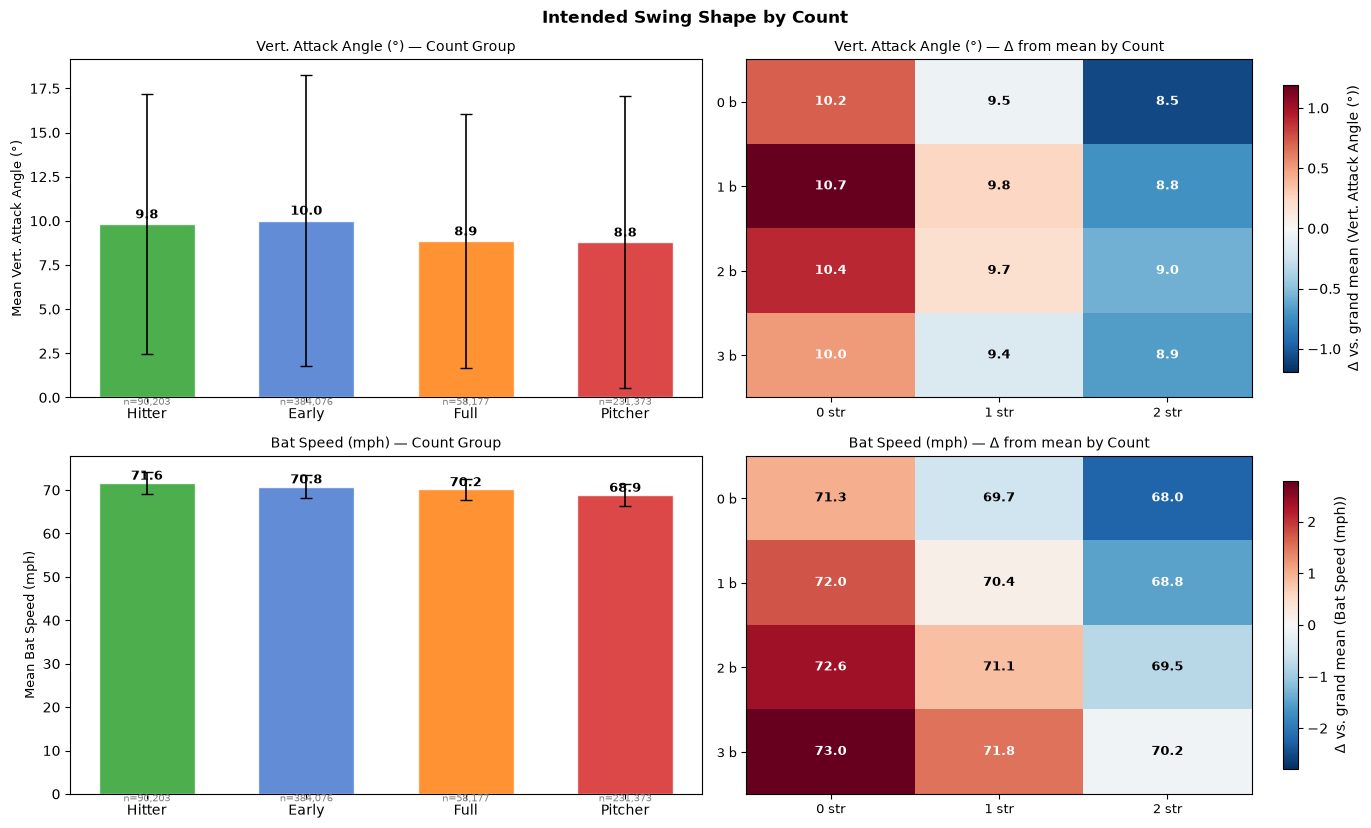

Saved results/plots/diagnostics/count_effects.png


In [7]:
LABELS = {"vert_attack_angle": "Vert. Attack Angle (\u00b0)", "bat_speed": "Bat Speed (mph)"}
COUNT_ORDER  = ["Hitter", "Early", "Full", "Pitcher"]
COUNT_COLORS = {"Hitter": "#2ca02c", "Early": "#4878d0",
                "Full": "#ff7f0e",   "Pitcher": "#d62728"}

sw   = pc()
intd = pd.read_parquet("models/intended_df.parquet")
df   = sw.join(intd)
df   = df[(df["is_swing"] == 1) & (df["bat_speed"] >= 50) &
          df["intended_vert_attack_angle"].notna()].copy()

metrics = ["vert_attack_angle", "bat_speed"]
fig, axes = plt.subplots(len(metrics), 2, figsize=(14, 4.2 * len(metrics)))
fig.suptitle("Intended Swing Shape by Count", fontsize=12, fontweight="bold")

df_cg = df.dropna(subset=["count_group"])
df_cm = df[(df["balls"].between(0, 3)) & (df["strikes"].between(0, 2))].copy()

for r, resp in enumerate(metrics):
    lbl  = LABELS[resp]; icol = f"intended_{resp}"

    ax = axes[r, 0]
    grp   = df_cg.groupby("count_group")[icol]
    means = grp.mean().reindex(COUNT_ORDER); sds = grp.std().reindex(COUNT_ORDER)
    bars  = ax.bar(COUNT_ORDER, means.values,
                   color=[COUNT_COLORS[g] for g in COUNT_ORDER],
                   alpha=0.85, edgecolor="white", width=0.6)
    ax.errorbar(COUNT_ORDER, means.values, yerr=sds.values,
                fmt="none", color="black", capsize=4, lw=1.2)
    for bar, m, sd in zip(bars, means.values, sds.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + sd*0.02,
                f"{m:.1f}", ha="center", va="bottom", fontsize=9, fontweight="bold")
    ax.set_ylabel(f"Mean {lbl}", fontsize=9)
    ax.set_title(f"{lbl} \u2014 Count Group", fontsize=10)
    ns = df_cg.groupby("count_group").size().reindex(COUNT_ORDER)
    for i, n in enumerate(ns):
        ax.text(i, ax.get_ylim()[0], f"n={n:,}", ha="center", va="top",
                fontsize=7, color="grey")

    ax = axes[r, 1]
    grand = df_cm[icol].mean()
    pivot = (df_cm.groupby(["balls", "strikes"])[icol].mean().subtract(grand)
             .unstack("strikes").reindex(index=[0,1,2,3], columns=[0,1,2]))
    raw   = (df_cm.groupby(["balls", "strikes"])[icol].mean()
             .unstack("strikes").reindex(index=[0,1,2,3], columns=[0,1,2]))
    vabs  = np.nanmax(np.abs(pivot.values))
    im = ax.imshow(pivot.values, cmap="RdBu_r", vmin=-vabs, vmax=vabs, aspect="auto")
    plt.colorbar(im, ax=ax, shrink=0.85, label=f"\u0394 vs. grand mean ({lbl})")
    for bi in range(4):
        for si in range(3):
            val = raw.iloc[bi, si]
            if not np.isnan(val):
                tc = "white" if abs(pivot.iloc[bi, si]) > vabs*0.4 else "black"
                ax.text(si, bi, f"{val:.1f}", ha="center", va="center",
                        fontsize=9, fontweight="bold", color=tc)
    ax.set_xticks([0,1,2]); ax.set_xticklabels(["0 str", "1 str", "2 str"], fontsize=9)
    ax.set_yticks([0,1,2,3]); ax.set_yticklabels(["0 b","1 b","2 b","3 b"], fontsize=9)
    ax.set_title(f"{lbl} \u2014 \u0394 from mean by Count", fontsize=10)

fig.tight_layout()
out = "results/plots/diagnostics/count_effects.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved {out}")


# Fixed Effects

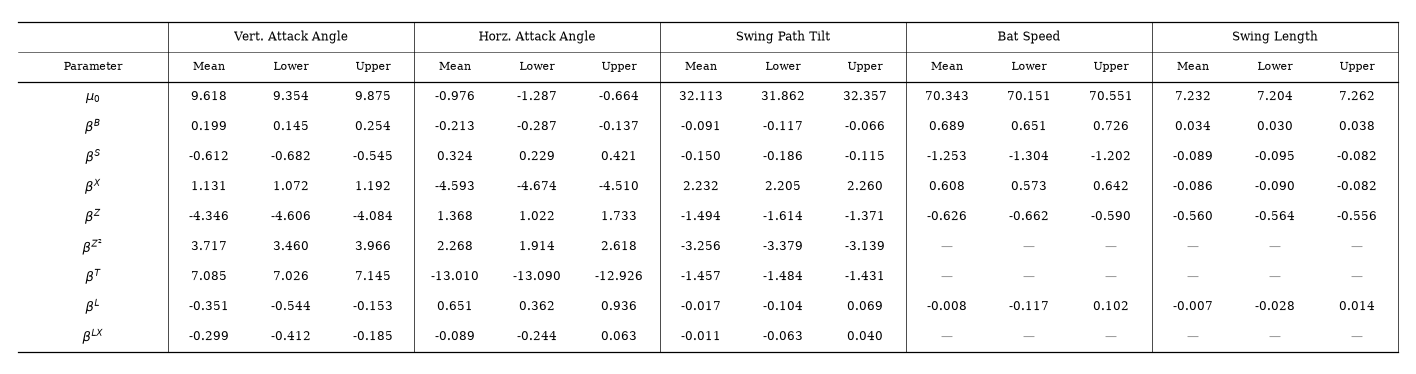

Saved results/plots/diagnostics/fixed_effects.png


In [8]:
RESPONSES = ["vert_attack_angle", "horz_attack_angle", "swing_path_tilt",
             "bat_speed", "swing_length"]
ANGULAR    = {"vert_attack_angle", "horz_attack_angle", "swing_path_tilt"}
PARAM_ORDER = ["Intercept", "scale(balls)", "scale(strikes)",
               "scale(plate_x_bat)", "scale(plate_z)", "scale(plate_z_sq)",
               "scale(offset_y_ms)", "pitcher_throws_L",
               "pitcher_throws_L:scale(plate_x_bat)"]
PARAM_GREEK = {
    "Intercept":                            r"$\mu_0$",
    "scale(balls)":                         r"$\beta^B$",
    "scale(strikes)":                       r"$\beta^S$",
    "scale(plate_x_bat)":                   r"$\beta^X$",
    "scale(plate_z)":                       r"$\beta^Z$",
    "scale(plate_z_sq)":                    r"$\beta^{Z^2}$",
    "scale(offset_y_ms)":                   r"$\beta^T$",
    "pitcher_throws_L":                     r"$\beta^L$",
    "pitcher_throws_L:scale(plate_x_bat)":  r"$\beta^{LX}$",
}
COL_GROUP = {"vert_attack_angle": "Vert. Attack Angle",
             "horz_attack_angle": "Horz. Attack Angle",
             "swing_path_tilt":   "Swing Path Tilt",
             "bat_speed":         "Bat Speed",
             "swing_length":      "Swing Length"}
RE_SFX    = ("_sigma", "_offset"); SKIP = {"sigma", "mu"}
ANG_ONLY  = {"scale(plate_z_sq)", "scale(offset_y_ms)",
             "pitcher_throws_L:scale(plate_x_bat)"}

result = joblib.load("models/intention_result.joblib")


def _fe(idata):
    post = idata.posterior; out = {}
    for v in post.data_vars:
        if (set(post[v].dims) == {"chain", "draw"} and v not in SKIP
                and not any(v.endswith(s) for s in RE_SFX)):
            draws = post[v].values.ravel()
            out[v] = {"mean": float(draws.mean()),
                      "lo":   float(np.percentile(draws, 2.5)),
                      "hi":   float(np.percentile(draws, 97.5))}
    return out


coefs = {r: _fe(result["idata"][r]) for r in RESPONSES}

LW=1.5; SW=0.82; RH=0.30; HH=0.30
ML=0.08; MR=0.08; MT=0.12; MB=0.12
NR=len(RESPONSES); NP=len(PARAM_ORDER)
fw = ML + LW + NR*3*SW + MR; fh = MT + 2*HH + NP*RH + MB
fig = plt.figure(figsize=(fw, fh)); ax = fig.add_axes([0,0,1,1])
ax.set_xlim(0, fw); ax.set_ylim(0, fh); ax.axis("off")

x0=ML; x1=fw-MR; yt=fh-MT; yg=yt-HH; ys=yg-HH; yb=MB
gx = lambda j: x0+LW+j*3*SW
cx = lambda j,k: gx(j)+(k+0.5)*SW

for y, lw in [(yt,0.9),(yg,0.4),(ys,0.9),(yb,0.9)]:
    ax.plot([x0,x1],[y,y],"k-",lw=lw)
for xv in [x0+LW]+[gx(j) for j in range(1,NR)]+[x1]:
    ax.plot([xv,xv],[yb,yt],"k-",lw=0.5)

for j,resp in enumerate(RESPONSES):
    ax.text(gx(j)+1.5*SW,(yt+yg)/2,COL_GROUP[resp],
            ha="center",va="center",fontsize=8.5,fontfamily="serif")
ax.text(x0+LW/2,(yg+ys)/2,"Parameter",ha="center",va="center",
        fontsize=8,fontfamily="serif")
for j in range(NR):
    for k,lbl in enumerate(["Mean","Lower","Upper"]):
        ax.text(cx(j,k),(yg+ys)/2,lbl,ha="center",va="center",
                fontsize=8,fontfamily="serif")
for i,param in enumerate(PARAM_ORDER):
    cy = ys-(i+0.5)*RH
    ax.text(x0+LW/2,cy,PARAM_GREEK[param],ha="center",va="center",
            fontsize=9,fontfamily="serif")
    for j,resp in enumerate(RESPONSES):
        if param in ANG_ONLY and resp not in ANGULAR:
            for k in range(3):
                ax.text(cx(j,k),cy,"\u2014",ha="center",va="center",
                        fontsize=8.5,color="#999",fontfamily="serif")
        else:
            s = coefs[resp].get(param)
            if s:
                for k,val in enumerate([s["mean"],s["lo"],s["hi"]]):
                    ax.text(cx(j,k),cy,f"{val:.3f}",ha="center",va="center",
                            fontsize=8.5,fontfamily="serif")
out = "results/plots/diagnostics/fixed_effects.png"
fig.savefig(out, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved {out}")
